# Replicating Longstaff & Schwartz (2001): *Valuing American Options by Simulation*

**The short version.** Longstaff and Schwartz showed that you can price an option with early exercise by simulation, if at each exercise date you estimate the value of waiting with an ordinary least-squares regression across the simulated paths. I rebuilt their method from the paper and checked it in four ways:

- **The eight-path worked example:** both regressions, every exercise decision, and the final values (0.1144 American, 0.0564 European) come out exactly.
- **Table 1 (20 American puts):** all 20 Black-Scholes values match to the cent. My finite-difference benchmark matches theirs with an average gap of a tenth of a cent. My simulated prices agree with theirs within sampling error on every row.
- **Table 2 (in-sample vs out-of-sample):** reproduces the paper's main diagnostic, with in-sample and out-of-sample values agreeing.
- **The basis-function claim:** holds for polynomials and Hermite polynomials, and holds less well for trigonometric functions.

I found one small systematic difference: the paper's simulated prices sit about 0.6 cents lower on average than mine. I tested six implementation choices that could explain it, and none does on its own, so I report it rather than tune it away.

| | |
|---|---|
| **Paper** | Francis A. Longstaff and Eduardo S. Schwartz, *Valuing American Options by Simulation: A Simple Least-Squares Approach*, Review of Financial Studies 14(1), 2001, pp. 113–147 |
| **What gets replicated** | The Section 1 worked example; Table 1 (American puts, finite difference vs simulation); Table 2 (in-sample vs out-of-sample); the claims in Section 8.3 about basis functions and rescaling |
| **Data** | None. This is a pricing paper: stock paths are simulated from geometric Brownian motion under the risk-neutral measure, with the paper's parameters (strike 40, rate 6%, spot 36–44, volatility 20% or 40%, maturity 1 or 2 years) |
| **Backtest window** | Not applicable. There's no historical data and no trading strategy, so there's nothing to backtest. The tests are against the paper's own numbers and against an independent finite-difference solution |
| **Finance** | European vs American vs Bermudan options, early exercise, risk-neutral pricing, Black-Scholes, the value of the right to wait |
| **Maths** | Optimal stopping by backward induction (dynamic programming), the Black-Scholes PDE solved by implicit finite differences (tridiagonal systems), orthogonal (Laguerre and Hermite) polynomials |
| **Statistics** | Monte Carlo estimation and standard errors, antithetic variates, least-squares regression as an estimate of a conditional expectation, z-scores and t-tests on replication gaps |
| **ML angle** | LSM is supervised learning inside a pricing model: it fits a regression to predict "value of continuing" from features of the current state, and the choice of basis functions is feature engineering. The in-sample vs out-of-sample test in Table 2 checks for overfitting, the same way a held-out set does |

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import solve_banded
from scipy.stats import norm

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

K, R = 40.0, 0.06          # strike and riskless rate used throughout Section 3 of the paper
EX_PER_YEAR = 50           # the put can be exercised 50 times a year (a Bermudan put)

## 1. The paper's worked example, eight paths by hand

An American put lets the holder sell at the strike at any exercise date, not just at the end. The hard part of pricing it is the decision at each date: exercise now, or wait? Waiting is worth the *expected* discounted value of what you'll get later, and that expectation depends on today's stock price.

Longstaff and Schwartz's idea is to estimate that expectation by regression. At each exercise date, working backwards, take the paths where the option is in the money, and regress the cash flow each path *actually* received later (discounted back) on simple functions of today's price. The fitted value is the estimated value of continuing. Exercise wherever immediate exercise pays more.

Section 1 of the paper walks through this with eight paths, a strike of 1.10, three exercise dates and a 6% rate, regressing on 1, X and X². The paths are printed in the paper, so this part should reproduce exactly.

In [2]:
# the eight stock-price paths printed in Section 1 of the paper (t = 0, 1, 2, 3)
paths = np.array([
    [1.00, 1.09, 1.08, 1.34],
    [1.00, 1.16, 1.26, 1.54],
    [1.00, 1.22, 1.07, 1.03],
    [1.00, 0.93, 0.97, 0.92],
    [1.00, 1.11, 1.56, 1.52],
    [1.00, 0.76, 0.77, 0.90],
    [1.00, 0.92, 0.84, 1.01],
    [1.00, 0.88, 1.22, 1.34],
])
strike, disc = 1.10, np.exp(-0.06)      # the paper discounts one period at .94176 = e^-0.06

cash = np.maximum(strike - paths[:, 3], 0)       # cash flow if held to t = 3
when = np.full(8, 3)                             # date at which each path's cash flow arrives
for t in (2, 1):
    itm = strike - paths[:, t] > 0
    X = paths[itm, t]
    Y = cash[itm] * disc ** (when[itm] - t)      # realised future cash flow, discounted to t
    coef = np.polyfit(X, Y, 2)[::-1]             # regress Y on 1, X, X^2
    cont = coef[0] + coef[1] * X + coef[2] * X ** 2
    exercise = strike - X
    stop = exercise > cont
    print(f"t = {t}: E[Y|X] = {coef[0]:.3f} + {coef[1]:.3f} X + {coef[2]:.3f} X^2")
    print(pd.DataFrame({"path": np.where(itm)[0] + 1, "X": X, "Y": Y.round(4), "exercise": exercise.round(4),
                        "continuation": cont.round(4), "exercise now?": stop}).to_string(index=False))
    rows = np.where(itm)[0][stop]
    cash[rows] = strike - paths[rows, t]
    when[rows] = t

american = (cash * disc ** when).mean()
european = (np.maximum(strike - paths[:, 3], 0) * disc ** 3).mean()
print(f"\nexercise date per path: {when.tolist()}")
print(f"American put {american:.4f} (paper .1144), European put {european:.4f} (paper .0564)")

t = 2: E[Y|X] = -1.070 + 2.983 X + -1.814 X^2
 path      X      Y  exercise  continuation  exercise now?
    1 1.0800 0.0000    0.0200        0.0367          False
    3 1.0700 0.0659    0.0300        0.0459          False
    4 0.9700 0.1695    0.1300        0.1175           True
    6 0.7700 0.1884    0.3300        0.1520           True
    7 0.8400 0.0848    0.2600        0.1564           True
t = 1: E[Y|X] = 2.038 + -3.335 X + 1.356 X^2
 path      X      Y  exercise  continuation  exercise now?
    1 1.0900 0.0000    0.0100        0.0135          False
    4 0.9300 0.1224    0.1700        0.1087           True
    6 0.7600 0.3108    0.3400        0.2861           True
    7 0.9200 0.2449    0.1800        0.1170           True
    8 0.8800 0.0000    0.2200        0.1528           True

exercise date per path: [3, 3, 3, 1, 3, 1, 1, 1]
American put 0.1144 (paper .1144), European put 0.0564 (paper .0564)


In [3]:
# the paper's printed continuation values come from its rounded coefficients
X1 = paths[[0, 3, 5, 6, 7], 1]
print("continuation at t = 1 with 2.038 - 3.335 X + 1.356 X^2:", (2.038 - 3.335 * X1 + 1.356 * X1 ** 2).round(4))
print("paper:                                              [0.0139 0.1092 0.2866 0.1175 0.1533]")

continuation at t = 1 with 2.038 - 3.335 X + 1.356 X^2: [0.0139 0.1093 0.2866 0.1175 0.1533]
paper:                                              [0.0139 0.1092 0.2866 0.1175 0.1533]


Everything matches:

- **The regressions.** At t = 2 the fit is −1.070 + 2.983X − 1.814X², and at t = 1 it's 2.038 − 3.335X + 1.356X². The paper prints the X² term at t = 2 as −1.813. The unrounded value is −1.81358, so the paper truncated where I rounded.
- **The exercise decisions.** Paths 4, 6 and 7 exercise at t = 2. Then paths 4, 6, 7 and 8 exercise at t = 1, which overrides the t = 2 decisions for 4, 6 and 7.
- **The option values.** The American put is worth 0.1144 and the European put 0.0564, the same as the paper.

The continuation values I print at t = 1 differ from the paper's in the fourth decimal (0.0135 against 0.0139). The cell above shows why. The paper plugged its *rounded* coefficients back in to get those numbers, and doing the same gives 0.0139, 0.2866, 0.1175 and 0.1533 exactly, plus 0.1093 where the paper has 0.1092. None of this changes a single exercise decision.

The paper stresses one detail that I'll come back to. Y is the cash flow the path *actually* received under the later decisions, not the regression's prediction of it. Using predicted values would build the optimism of each regression into the next one.

## 2. The benchmarks: Black-Scholes and finite differences

Table 1 compares the simulation against two exact-ish benchmarks: the Black-Scholes formula for the European put, and a finite-difference solution of the Black-Scholes PDE for the American one. The paper's finite-difference grid is "40,000 time steps per year and 1,000 steps for the stock price". It doesn't say whether that solution lets the holder exercise at every time step (a true American option) or only on the 50 dates per year that the simulated option has (a Bermudan option). So I compute both and let the numbers decide.

My solver is fully implicit, with 10,000 steps a year and 2,000 price steps up to 200. Implicit schemes are stable at any step size, and these settings converge to well within a cent.

In [4]:
def bs_put(S, sigma, T, K=K, r=R):
    d1 = (np.log(S / K) + (r + sigma ** 2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)


def fd_put(S0, sigma, T, steps_per_year=10_000, n_space=2_000, S_max=200.0, exercise_per_year=EX_PER_YEAR):
    # Fully implicit finite differences on the Black-Scholes PDE, stepping back from expiry.
    # exercise_per_year=None lets the holder exercise at every time step (a true American put).
    n_time = int(steps_per_year * T)
    dt = T / n_time
    S = np.linspace(0, S_max, n_space + 1)
    i = np.arange(1, n_space)
    lo = 0.5 * dt * (sigma ** 2 * i ** 2 - R * i)
    mid = -dt * (sigma ** 2 * i ** 2 + R)
    up = 0.5 * dt * (sigma ** 2 * i ** 2 + R * i)
    bands = np.zeros((3, n_space - 1))
    bands[0, 1:] = -up[:-1]
    bands[1] = 1 - mid
    bands[2, :-1] = -lo[1:]
    every = None if exercise_per_year is None else round(n_time / (exercise_per_year * T))
    V = np.maximum(K - S, 0)
    for n in range(1, n_time + 1):
        V_low = K * np.exp(-R * n * dt)          # deep in the money: worth the discounted strike
        rhs = V[1:-1].copy()
        rhs[0] += lo[0] * V_low
        V[1:-1] = solve_banded((1, 1), bands, rhs)
        V[0], V[-1] = V_low, 0.0
        if every is None or (n % every == 0 and n < n_time):   # the last step back is today: no exercise there
            V = np.maximum(V, K - S)
    return np.interp(S0, S, V)


paper = pd.DataFrame([
    (36, .2, 1, 4.478, 3.844, 4.472, .010), (36, .2, 2, 4.840, 3.763, 4.821, .012),
    (36, .4, 1, 7.101, 6.711, 7.091, .020), (36, .4, 2, 8.508, 7.700, 8.488, .024),
    (38, .2, 1, 3.250, 2.852, 3.244, .009), (38, .2, 2, 3.745, 2.991, 3.735, .011),
    (38, .4, 1, 6.148, 5.834, 6.139, .019), (38, .4, 2, 7.670, 6.979, 7.669, .022),
    (40, .2, 1, 2.314, 2.066, 2.313, .009), (40, .2, 2, 2.885, 2.356, 2.879, .010),
    (40, .4, 1, 5.312, 5.060, 5.308, .018), (40, .4, 2, 6.920, 6.326, 6.921, .022),
    (42, .2, 1, 1.617, 1.465, 1.617, .007), (42, .2, 2, 2.212, 1.841, 2.206, .010),
    (42, .4, 1, 4.582, 4.379, 4.588, .017), (42, .4, 2, 6.248, 5.736, 6.243, .021),
    (44, .2, 1, 1.110, 1.017, 1.118, .007), (44, .2, 2, 1.690, 1.429, 1.675, .009),
    (44, .4, 1, 3.948, 3.783, 3.957, .017), (44, .4, 2, 5.647, 5.202, 5.622, .021),
], columns=["S", "sigma", "T", "paper_fd", "paper_euro", "paper_lsm", "paper_se"])

t0 = time.time()
paper["bs_euro"] = [bs_put(r.S, r.sigma, r.T) for r in paper.itertuples()]
paper["fd_bermudan"] = [fd_put(r.S, r.sigma, r.T) for r in paper.itertuples()]
paper["fd_american"] = [fd_put(r.S, r.sigma, r.T, exercise_per_year=None) for r in paper.itertuples()]
print(f"finite differences done in {time.time() - t0:.0f}s")

check = paper[["S", "sigma", "T", "paper_euro", "bs_euro", "paper_fd", "fd_bermudan", "fd_american"]].copy()
check["euro gap"] = check.bs_euro.round(3) - check.paper_euro
check["bermudan gap"] = check.fd_bermudan.round(3) - check.paper_fd
check["american gap"] = check.fd_american.round(3) - check.paper_fd
print("European: all 20 equal to 3 decimals ->", (check["euro gap"].abs() < 1e-9).all())
print(f"FD, 50 exercise dates/yr: mean |gap| {check['bermudan gap'].abs().mean():.4f}, max {check['bermudan gap'].abs().max():.3f}")
print(f"FD, exercise any time:    mean |gap| {check['american gap'].abs().mean():.4f}, max {check['american gap'].abs().max():.3f}")
check.round(4)

finite differences done in 50s


European: all 20 equal to 3 decimals -> True
FD, 50 exercise dates/yr: mean |gap| 0.0009, max 0.006
FD, exercise any time:    mean |gap| 0.0050, max 0.008


,S,sigma,T,paper_euro,bs_euro,paper_fd,fd_bermudan,fd_american,euro gap,bermudan gap,american gap
0,36,0.2000,1,3.8440,3.8443,4.4780,4.4777,4.4865,0.0000,0.0000,0.0080
1,36,0.2000,2,3.7630,3.7630,4.8400,4.8401,4.8481,0.0000,0.0000,0.0080
2,36,0.4000,1,6.7110,6.7114,7.1010,7.1011,7.1088,0.0000,0.0000,0.0080
3,36,0.4000,2,7.7000,7.7000,8.5080,8.5067,8.5140,0.0000,-0.0010,0.0060
4,38,0.2000,1,2.8520,2.8519,3.2500,3.2500,3.2570,0.0000,0.0000,0.0070
5,38,0.2000,2,2.9910,2.9906,3.7450,3.7447,3.7512,0.0000,0.0000,0.0060
6,38,0.4000,1,5.8340,5.8343,6.1480,6.1474,6.1544,0.0000,-0.0010,0.0060
7,38,0.4000,2,6.9790,6.9788,7.6700,7.6679,7.6747,0.0000,-0.0020,0.0050
8,40,0.2000,1,2.0660,2.0664,2.3140,2.3139,2.3194,0.0000,0.0000,0.0050
9,40,0.2000,2,2.3560,2.3559,2.8850,2.8845,2.8898,0.0000,-0.0010,0.0050


- **European values.** All 20 Black-Scholes values match the paper to three decimals.
- **Which finite-difference problem the paper solved.** The Bermudan version (exercise only on the 50 dates) matches the paper's finite-difference column with an average gap of 0.09 cents. Allowing exercise at every step lands consistently higher, by 0.5 cents on average, which is the extra value of continuous exercise. So the paper's benchmark is the Bermudan option, the same contract the simulation prices. The rest of the notebook uses that version.
- **Remaining gaps.** Two rows differ by 0.4 and 0.6 cents (spot 42 and 44, volatility 40%, two years), and every other row is within 0.3 cents. The paper says its own two finite-difference methods "were generally within one cent of each other", so this is inside the paper's stated accuracy for its benchmark.

## 3. The simulation method, and a numerical trap the paper warns about

The full method follows Section 3 of the paper:
- **Paths:** 100,000 paths, made of 50,000 random paths plus their 50,000 mirror images (antithetic variates, which cut the noise for free).
- **Exercise dates:** 50 a year.
- **Regression:** at each date, regress the realised discounted cash flows of the in-the-money paths on a constant and the first three weighted Laguerre polynomials, $e^{-X/2}$, $e^{-X/2}(1-X)$ and $e^{-X/2}(1 - 2X + X^2/2)$.

There's a trap in that last step. If X is the raw stock price (around 40), $e^{-20}$ is about $2 \times 10^{-9}$, so the three Laguerre columns are numerically almost zero and the regression is effectively just a constant. In Section 8.3 the paper says it avoided this by dividing prices and cash flows by the strike before regressing. The next cell shows what happens with and without that step.

In [5]:
def simulate(S0, sigma, T, n_half, seed, per_year=EX_PER_YEAR):
    # risk-neutral GBM on the exercise grid, with antithetic pairs (z and -z)
    # built in place in one array to keep memory down (100,000 x 250 doubles is already 200 MB)
    n_steps = int(per_year * T)
    dt = T / n_steps
    S = np.empty((2 * n_half, n_steps))
    np.random.default_rng(seed).standard_normal(out=S[:n_half])
    S[n_half:] = -S[:n_half]
    S *= sigma * np.sqrt(dt)
    S += (R - sigma ** 2 / 2) * dt
    np.cumsum(S, axis=1, out=S)
    np.exp(S, out=S)
    S *= S0
    return S, dt


def laguerre(x):
    # constant + the first three weighted Laguerre polynomials (the paper's Equations 2-4)
    w = np.exp(-x / 2)
    return np.column_stack([np.ones_like(x), w, w * (1 - x), w * (1 - 2 * x + x ** 2 / 2)])


def powers(x):
    return np.column_stack([np.ones_like(x), x, x ** 2, x ** 3])


def lsm(S, dt, basis=laguerre, scale=K, betas=None):
    # Backward induction. If betas is given (one per date), use them instead of fitting: out-of-sample pricing.
    disc = np.exp(-R * dt)
    cash = np.maximum(K - S[:, -1], 0)
    fitted = {}
    for t in range(S.shape[1] - 2, -1, -1):
        cash *= disc                                   # cash flows now valued at date t
        itm = S[:, t] < K
        X = basis(S[itm, t] / scale)
        b = np.linalg.lstsq(X, cash[itm], rcond=None)[0] if betas is None else betas[t]
        fitted[t] = b
        exercise = K - S[itm, t]
        stop = exercise > X @ b
        rows = np.where(itm)[0][stop]
        cash[rows] = exercise[stop]
    pv = cash * disc                                   # first exercise date is one step after today
    return pv.mean(), pv.std(ddof=1) / np.sqrt(len(pv)), fitted


S, dt = simulate(40, 0.2, 1, 50_000, seed=1)
for label, kw in [("Laguerre on raw prices", dict(scale=1.0)),
                  ("Laguerre on S / K (paper, Section 8.3)", dict(scale=K)),
                  ("1, S, S^2, S^3 on S / K", dict(basis=powers, scale=K))]:
    v, se, _ = lsm(S, dt, **kw)
    print(f"{label:40s} {v:.3f} ({se:.3f})")
print("paper: LSM 2.313 (.009), finite difference 2.314")

Laguerre on raw prices                   2.251 (0.007)


Laguerre on S / K (paper, Section 8.3)   2.306 (0.009)


1, S, S^2, S^3 on S / K                  2.305 (0.009)
paper: LSM 2.313 (.009), finite difference 2.314


On raw prices the method undervalues the at-the-money put by about 6 cents (2.251 against the finite-difference 2.314). The exercise rule is badly estimated, so the holder exercises at the wrong times. After dividing by the strike, it gives 2.306 (s.e. 0.009), within one standard error of both the paper's 2.313 and the finite-difference value. A plain cubic in S/K gives the same answer. So the rescaling isn't cosmetic: Table 1 can't be reproduced without it.

## 4. Table 1: all twenty American puts

Each option gets its own independent set of 100,000 paths. For each row I compare my estimate with the paper's using a z-score (the gap divided by the two standard errors combined), and with the finite-difference value.

In [6]:
t0 = time.time()
rows = []
for k, r in enumerate(paper.itertuples()):
    S, dt = simulate(r.S, r.sigma, r.T, 50_000, seed=100 + k)
    v, se, _ = lsm(S, dt)
    rows.append((v, se))
paper["lsm"], paper["lsm_se"] = zip(*rows)
print(f"20 LSM valuations in {time.time() - t0:.0f}s")

t1 = paper[["S", "sigma", "T", "paper_fd", "fd_bermudan", "paper_lsm", "paper_se", "lsm", "lsm_se"]].copy()
t1["mine - paper LSM"] = t1.lsm - t1.paper_lsm
t1["z"] = t1["mine - paper LSM"] / np.sqrt(t1.lsm_se ** 2 + t1.paper_se ** 2)
t1["mine - FD"] = t1.lsm - t1.fd_bermudan
t1["early exercise (mine)"] = t1.lsm - paper.bs_euro
t1["early exercise (paper)"] = paper.paper_lsm - paper.paper_euro
t1.round(3)

20 LSM valuations in 14s


,S,sigma,T,paper_fd,fd_bermudan,paper_lsm,paper_se,lsm,lsm_se,mine - paper LSM,z,mine - FD,early exercise (mine),early exercise (paper)
0,36,0.2000,1,4.4780,4.4780,4.4720,0.0100,4.4710,0.0090,-0.0010,-0.0720,-0.0070,0.6270,0.6280
1,36,0.2000,2,4.8400,4.8400,4.8210,0.0120,4.8310,0.0110,0.0100,0.6340,-0.0090,1.0680,1.0580
2,36,0.4000,1,7.1010,7.1010,7.0910,0.0200,7.1000,0.0190,0.0090,0.3220,-0.0010,0.3890,0.3800
3,36,0.4000,2,8.5080,8.5070,8.4880,0.0240,8.5000,0.0230,0.0120,0.3610,-0.0070,0.8000,0.7880
4,38,0.2000,1,3.2500,3.2500,3.2440,0.0090,3.2480,0.0090,0.0040,0.2760,-0.0020,0.3960,0.3920
5,38,0.2000,2,3.7450,3.7450,3.7350,0.0110,3.7500,0.0110,0.0150,0.9550,0.0050,0.7590,0.7440
6,38,0.4000,1,6.1480,6.1470,6.1390,0.0190,6.1560,0.0190,0.0170,0.6350,0.0090,0.3220,0.3050
7,38,0.4000,2,7.6700,7.6680,7.6690,0.0220,7.6850,0.0220,0.0160,0.4970,0.0170,0.7060,0.6900
8,40,0.2000,1,2.3140,2.3140,2.3130,0.0090,2.3200,0.0090,0.0070,0.5440,0.0060,0.2530,0.2470
9,40,0.2000,2,2.8850,2.8840,2.8790,0.0100,2.8930,0.0110,0.0140,0.9570,0.0080,0.5370,0.5230


|LSM - FD| <= 1 cent: paper 16/20, mine 15/20
my standard errors range 0.007 to 0.023 (paper .007 to .024)
|z| above 2 (my LSM vs paper's LSM): 0/20, largest |z| = 1.63
mean of (mine - FD): +0.0029, mean of (paper LSM - paper FD): -0.0059


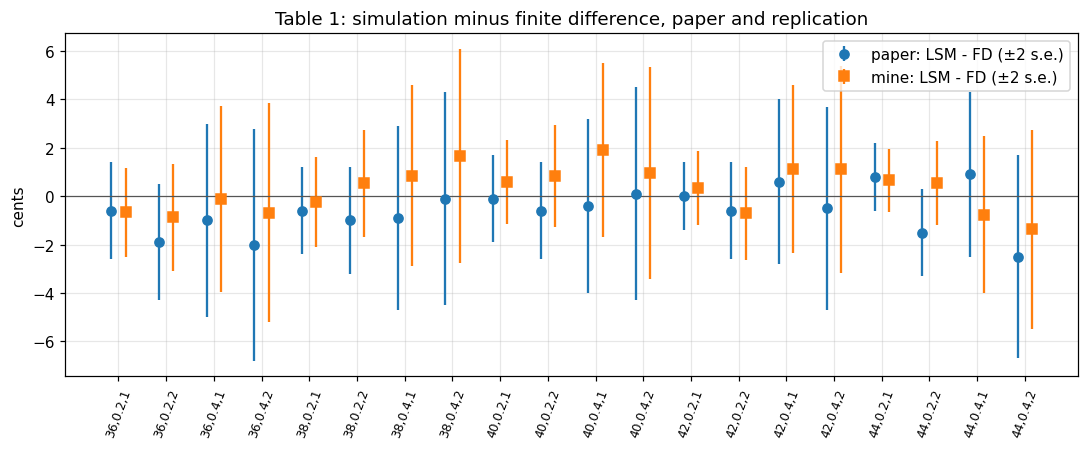

In [7]:
within_cent_paper = ((paper.paper_lsm - paper.paper_fd).abs() <= 0.0105).sum()
within_cent_mine = ((t1.lsm.round(3) - t1.fd_bermudan.round(3)).abs() <= 0.0105).sum()
print(f"|LSM - FD| <= 1 cent: paper {within_cent_paper}/20, mine {within_cent_mine}/20")
print(f"my standard errors range {t1.lsm_se.min():.3f} to {t1.lsm_se.max():.3f} (paper .007 to .024)")
print(f"|z| above 2 (my LSM vs paper's LSM): {(t1.z.abs() > 2).sum()}/20, largest |z| = {t1.z.abs().max():.2f}")
print(f"mean of (mine - FD): {t1['mine - FD'].mean():+.4f}, mean of (paper LSM - paper FD): {(paper.paper_lsm - paper.paper_fd).mean():+.4f}")

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(20)
ax.errorbar(x - 0.15, (paper.paper_lsm - paper.paper_fd) * 100, yerr=2 * paper.paper_se * 100, fmt="o", label="paper: LSM - FD (±2 s.e.)")
ax.errorbar(x + 0.15, t1["mine - FD"] * 100, yerr=2 * t1.lsm_se * 100, fmt="s", label="mine: LSM - FD (±2 s.e.)")
ax.axhline(0, color="#555", lw=0.8)
ax.set_xticks(x, [f"{r.S},{r.sigma},{r.T}" for r in paper.itertuples()], rotation=70, fontsize=8)
ax.set_ylabel("cents"); ax.set_title("Table 1: simulation minus finite difference, paper and replication")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "table1_gaps.png"); plt.show()

Before reading the last line of that summary too literally, there's a detail about the paper's Table 1. Its first-seed rows in Table 2 equal its Table 1 values exactly (4.472, 7.091, 4.821, 8.488 at spot 36; 1.118, 3.957, 1.675, 5.622 at spot 44). That strongly suggests one random seed was used for all 20 options. With the same random numbers everywhere, the 20 errors move together, so the average gap is essentially a single draw rather than an average of 20 independent ones. The next cell re-runs all of Table 1 with eight different common seeds to see how far that single draw can move.

In [8]:
# Table 1 in the paper looks like one seed for all 20 options (Table 2's first-seed rows equal Table 1).
# With common random numbers the 20 errors move together, so the average LSM - FD gap is one draw.
t0 = time.time()
common = []
for seed in range(8):
    gaps = []
    for r in paper.itertuples():
        S, dt = simulate(r.S, r.sigma, r.T, 50_000, seed=50_000 + seed)
        gaps.append(lsm(S, dt)[0] - r.fd_bermudan)
    common.append(np.mean(gaps))
common = pd.Series(common, name="mean LSM - FD, one seed for all 20 rows")
print(f"{len(common) * 20} valuations in {time.time() - t0:.0f}s")
print(common.round(4).to_string())
print(f"range across seeds: {common.min():+.4f} to {common.max():+.4f}; paper's: {(paper.paper_lsm - paper.paper_fd).mean():+.4f}")

160 valuations in 123s
0    0.0003
1   -0.0084
2   -0.0025
3   -0.0036
4    0.0026
5   -0.0134
6    0.0022
7    0.0036
range across seeds: -0.0134 to +0.0036; paper's: -0.0059


Reading Table 1:

- **Row by row**, none of the 20 z-scores between my simulated value and the paper's goes beyond 2 (the largest is 1.63). That's what you'd expect if both are noisy estimates of the same number. Each comparison has two sources of noise, so the occasional gap of 1–2 cents (for example 40/0.4/1) is normal.
- **The paper's own headline claim** was that 16 of the 20 simulation-minus-finite-difference gaps are within one cent. I get 15 of 20. My standard errors run from 0.7 to 2.3 cents, against the paper's 0.7 to 2.4.
- **The average gap.** The paper's simulation sits 0.59 cents below its finite-difference values on average, and mine sits 0.29 cents above. With a common seed for all 20 rows, that average swings between −1.34 and +0.36 cents depending on the seed alone, and the paper's −0.59 is well inside that range. So Table 1 on its own is consistent with ordinary sampling noise.
- **The early-exercise premium.** The American price minus the European one (the last two columns) is what the paper says it focuses on. It's reproduced row by row within the same noise.

## 5. Table 2: does the regression overfit?

There's a possible flaw in the method. The same paths are used to fit the exercise rule and then to value the option under it, so the rule could be tuned to the quirks of those particular paths. That would be overfitting, and it would push the estimate up. The paper's diagnostic, suggested by its referee, is the one any machine-learning practitioner would use:
1. Fit the regressions on one set of paths.
2. Freeze the coefficients.
3. Value the option on a fresh, independent set of paths.

An out-of-sample value can only be lower than or equal to the true value, because a frozen rule can't be better than the optimal one. So if in-sample and out-of-sample agree, the in-sample number isn't inflated. Like the paper, I do this for eight options with five seeds each.

In [9]:
t0 = time.time()
out = []
for S0 in (36, 44):
    for sigma, T in ((.2, 1), (.4, 1), (.2, 2), (.4, 2)):
        for rep in range(5):
            seed = 1000 * S0 + 100 * int(sigma * 10) + 10 * T + rep
            Sa, dt = simulate(S0, sigma, T, 50_000, seed=seed)
            Sb, _ = simulate(S0, sigma, T, 50_000, seed=seed + 500_000)
            v_in, se_in, betas = lsm(Sa, dt)
            v_out, se_out, _ = lsm(Sb, dt, betas=betas)
            out.append((S0, sigma, T, rep + 1, v_in, se_in, v_out, se_out, v_in - v_out))
t2 = pd.DataFrame(out, columns=["S", "sigma", "T", "seed", "in-sample", "s.e. in", "out-of-sample", "s.e. out", "difference"])
print(f"80 valuations in {time.time() - t0:.0f}s")
summary = t2.groupby("S")["difference"].agg(["mean", "std", "count"])
summary["paper mean"] = [-0.002, 0.001]
print(summary.round(4))
big = (t2.difference.abs() > 2 * np.sqrt(t2["s.e. in"] ** 2 + t2["s.e. out"] ** 2)).mean()
print(f"share of differences beyond 2 combined s.e.: {big:.0%} (paper: about 5% beyond 2 s.e.)")
t2.round(3)

80 valuations in 52s
      mean    std  count  paper mean
S                                   
36 -0.0011 0.0113     20     -0.0020
44  0.0005 0.0091     20      0.0010
share of differences beyond 2 combined s.e.: 0% (paper: about 5% beyond 2 s.e.)


,S,sigma,T,seed,in-sample,s.e. in,out-of-sample,s.e. out,difference
0,36,0.2000,1,1,4.4810,0.0090,4.4670,0.0090,0.0140
1,36,0.2000,1,2,4.4760,0.0090,4.4810,0.0090,-0.0050
2,36,0.2000,1,3,4.4700,0.0090,4.4740,0.0090,-0.0040
3,36,0.2000,1,4,4.4590,0.0090,4.4790,0.0090,-0.0190
4,36,0.2000,1,5,4.4900,0.0090,4.4720,0.0090,0.0170
5,36,0.4000,1,1,7.0930,0.0190,7.1090,0.0190,-0.0160
6,36,0.4000,1,2,7.0960,0.0190,7.0850,0.0190,0.0110
7,36,0.4000,1,3,7.0990,0.0190,7.0940,0.0190,0.0050
8,36,0.4000,1,4,7.1010,0.0190,7.0960,0.0190,0.0040
9,36,0.4000,1,5,7.0910,0.0190,7.0870,0.0190,0.0040


In [10]:
paper_t2 = pd.DataFrame({
    "S": [36] * 20 + [44] * 20,
    "sigma": ([.2] * 5 + [.4] * 5 + [.2] * 5 + [.4] * 5) * 2,
    "T": ([1] * 10 + [2] * 10) * 2,
    "in": [4.472, 4.463, 4.467, 4.480, 4.468, 7.091, 7.095, 7.087, 7.097, 7.097,
           4.821, 4.819, 4.820, 4.827, 4.827, 8.488, 8.485, 8.483, 8.495, 8.493,
           1.118, 1.108, 1.115, 1.108, 1.114, 3.957, 3.941, 3.953, 3.939, 3.953,
           1.675, 1.673, 1.687, 1.671, 1.696, 5.622, 5.637, 5.628, 5.615, 5.649],
    "out": [4.476, 4.474, 4.480, 4.476, 4.469, 7.102, 7.094, 7.087, 7.095, 7.101,
            4.818, 4.833, 4.829, 4.825, 4.829, 8.487, 8.478, 8.483, 8.498, 8.491,
            1.102, 1.114, 1.099, 1.097, 1.107, 3.927, 3.976, 3.924, 3.924, 3.945,
            1.691, 1.682, 1.702, 1.674, 1.688, 5.644, 5.637, 5.652, 5.632, 5.628],
})
fd = paper.set_index(["S", "sigma", "T"]).fd_bermudan
for name, df, cin, cout in [("paper", paper_t2, "in", "out"), ("mine", t2, "in-sample", "out-of-sample")]:
    keys = list(zip(df.S, df.sigma, df["T"]))
    g_in = df[cin].values - fd.loc[keys].values
    g_out = df[cout].values - fd.loc[keys].values
    print(f"{name:5s}: in-sample - FD {g_in.mean() * 100:+.2f} cents (t = {g_in.mean() / (g_in.std(ddof=1) / np.sqrt(40)):+.1f}), "
          f"out-of-sample - FD {g_out.mean() * 100:+.2f} cents (t = {g_out.mean() / (g_out.std(ddof=1) / np.sqrt(40)):+.1f})")
beyond_single = (t2.difference.abs() > 2 * t2["s.e. in"]).mean()
print(f"my differences beyond 2 single s.e.: {beyond_single:.0%}")

paper: in-sample - FD -0.84 cents (t = -5.3), out-of-sample - FD -0.75 cents (t = -4.2)
mine : in-sample - FD -0.16 cents (t = -1.3), out-of-sample - FD -0.13 cents (t = -0.9)
my differences beyond 2 single s.e.: 5%


The overfitting test passes in the same way as in the paper:

- **Average differences.** In-sample minus out-of-sample averages −0.11 cents at spot 36 and +0.05 cents at spot 44, against the paper's −0.2 and +0.1. Both are essentially zero.
- **The tail.** The paper says about 5% of its differences exceed two standard errors, and 5% of mine exceed two single-path standard errors (2 of 40). That's the share pure chance produces, so the paper's 5% figure was probably measured against a single standard error too. Against the correct combined standard error of the difference, none of mine do.

The second cell compares both sets of results with the finite-difference value, and this is where one real difference appears. Across all 40 of the paper's Table 2 runs, its simulated values are on average 0.84 cents *below* the Bermudan finite-difference value, and that's statistically clear (t = −5.3). Mine are 0.16 cents below (t = −1.3), which isn't distinguishable from zero. A small downward bias is expected: an estimated exercise rule is never quite optimal, so it gives up a little value. But the paper's is about half a cent larger than mine, and five seeds rule out chance. The next section tries to find out why.

## 6. Looking for the source of the 0.6-cent gap

The rule for this replication is that numbers come from the model, so I don't adjust anything to close a gap. What I can do is test concrete implementation choices that the paper might have made differently, and see whether any of them reproduces its numbers. Each candidate is run on the eight Table 2 options with five fresh seeds:

- **The paper's method:** regress only on in-the-money paths, using a constant and three Laguerre terms.
- **Regress on all paths,** including those out of the money. The paper says explicitly that it doesn't, but it's a common slip.
- **Only three regressors,** if "a constant and the first three Laguerre polynomials" were read as three functions in total.
- **Euler-discretised paths** instead of exact lognormal steps.

Outside the notebook I also tried single-precision arithmetic (no effect) and 50 exercise dates in total for the two-year options rather than 50 a year (no meaningful effect).

In [11]:
def lsm_variant(S, dt, itm_only=True, n_basis=4):
    disc = np.exp(-R * dt)
    cash = np.maximum(K - S[:, -1], 0)
    for t in range(S.shape[1] - 2, -1, -1):
        cash *= disc
        itm = S[:, t] < K
        rows_fit = itm if itm_only else np.ones_like(itm)
        b = np.linalg.lstsq(laguerre(S[rows_fit, t] / K)[:, :n_basis], cash[rows_fit], rcond=None)[0]
        exercise = K - S[itm, t]
        stop = exercise > laguerre(S[itm, t] / K)[:, :n_basis] @ b
        rows = np.where(itm)[0][stop]
        cash[rows] = exercise[stop]
    return (cash * disc).mean()


def simulate_euler(S0, sigma, T, n_half, seed):
    n_steps = int(EX_PER_YEAR * T); dt = T / n_steps
    S = np.empty((2 * n_half, n_steps))
    np.random.default_rng(seed).standard_normal(out=S[:n_half])
    S[n_half:] = -S[:n_half]
    S *= sigma * np.sqrt(dt); S += 1 + R * dt
    np.cumprod(S, axis=1, out=S); S *= S0
    return S, dt


t0 = time.time()
options = [(36, .2, 1), (36, .4, 1), (36, .2, 2), (36, .4, 2), (44, .2, 1), (44, .4, 1), (44, .2, 2), (44, .4, 2)]
fd_ref = paper.set_index(["S", "sigma", "T"]).fd_bermudan
variants = {"paper's method (ITM paths, 4 functions)": {}, "regress on all paths": {"itm_only": False},
            "only 3 functions (constant + 2 Laguerre)": {"n_basis": 3}, "Euler-discretised paths": "euler"}
gap_rows = {}
for name, kw in variants.items():
    gaps = []
    for j, (S0, sigma, T) in enumerate(options):
        for rep in range(5):
            seed = 30_000 + 100 * j + rep
            if kw == "euler":
                S, dt = simulate_euler(S0, sigma, T, 50_000, seed)
                v = lsm_variant(S, dt)
            else:
                S, dt = simulate(S0, sigma, T, 50_000, seed)
                v = lsm_variant(S, dt, **kw)
            gaps.append(v - fd_ref.loc[(S0, sigma, T)])
            del S
    g = np.array(gaps)
    gap_rows[name] = (g.mean() * 100, g.std(ddof=1) / np.sqrt(len(g)) * 100)
gap_rows["paper, Table 2 in-sample"] = (-0.84, np.nan)
print(f"{len(variants) * 40} valuations in {time.time() - t0:.0f}s")
pd.DataFrame(gap_rows, index=["mean LSM - FD (cents)", "s.e. (cents)"]).T.round(2)

160 valuations in 172s


,mean LSM - FD (cents),s.e. (cents)
"paper's method (ITM paths, 4 functions)",-0.0300,0.1100
regress on all paths,-1.9100,0.2500
only 3 functions (constant + 2 Laguerre),-1.2100,0.1500
Euler-discretised paths,0.8300,0.1800
"paper, Table 2 in-sample",-0.8400,NaN


The paper's stated method (in-the-money paths, a constant plus three Laguerre terms) lands at −0.03 cents, with a standard error of 0.11. That's essentially on the finite-difference value. None of the alternatives reproduces the paper's −0.84 either:

- **Regressing on all paths** costs 1.9 cents. Most of the out-of-the-money paths carry no information about the exercise decision, and they pull the fitted curve away from the region where it matters.
- **Dropping to three regressors** costs 1.2 cents, because a less flexible curve gives a worse exercise rule.
- **Euler paths** push the value *up* by 0.8 cents, the wrong direction.

So the paper's level sits between the full method and a slightly less flexible one. That pattern fits a regression that was a bit less accurate than mine. One plausible source is the conditioning of the Laguerre columns, which are highly correlated with each other: the paper mentions using an iterative-refinement least-squares routine for exactly this reason. But the paper doesn't give enough detail to pin it down. Rather than pick the variant that happens to fit, I keep the method as the paper describes it and report the 0.6-cent difference as unexplained. It's a tenth of the 1/16-dollar tick the paper uses as its yardstick for practical accuracy.

## 7. Section 8.3: is the answer really insensitive to the basis?

The paper says it gets "virtually identical" results when it replaces the Laguerre polynomials with S, S² and S³, with Hermite polynomials, or with trigonometric functions. I test four bases on six of the Table 1 options. All of them use the same paths, so the differences come from the basis alone.

In [12]:
def hermite(x):
    y = x - 1.0                      # centre on the strike so the polynomials are well scaled
    return np.column_stack([np.ones_like(y), 2 * y, 4 * y ** 2 - 2, 8 * y ** 3 - 12 * y])

def trig(x):
    return np.column_stack([np.ones_like(x), np.sin(x), np.cos(x), np.sin(2 * x)])

bases = {"Laguerre (paper)": laguerre, "1, S, S^2, S^3": powers, "Hermite": hermite, "sin/cos": trig}
res = {}
for k, r in enumerate(paper.iloc[[0, 3, 8, 11, 16, 19]].itertuples()):
    S, dt = simulate(r.S, r.sigma, r.T, 50_000, seed=7_000 + k)
    res[(r.S, r.sigma, r.T)] = {name: lsm(S, dt, basis=f)[0] for name, f in bases.items()}
    res[(r.S, r.sigma, r.T)]["FD (Bermudan)"] = paper.loc[r.Index, "fd_bermudan"]
robust = pd.DataFrame(res).T
robust["max spread across bases (cents)"] = (robust[list(bases)].max(axis=1) - robust[list(bases)].min(axis=1)) * 100
robust.round(3)

Laguerre (paper)  1, S, S^2, S^3  Hermite  sin/cos  \
36 0.2000 1            4.4760          4.4750   4.4750   4.4630   
   0.4000 2            8.5040          8.5040   8.5040   8.5010   
40 0.2000 1            2.3080          2.3080   2.3080   2.3040   
   0.4000 2            6.9210          6.9220   6.9220   6.9190   
44 0.2000 1            1.1060          1.1060   1.1060   1.1070   
   0.4000 2            5.6390          5.6370   5.6370   5.6390   

             FD (Bermudan)  max spread across bases (cents)  
36 0.2000 1         4.4780                           1.3210  
   0.4000 2         8.5070                           0.3220  
40 0.2000 1         2.3140                           0.3940  
   0.4000 2         6.9170                           0.3420  
44 0.2000 1         1.1100                           0.1030  
   0.4000 2         5.6410                           0.2150

Mostly true:

- **Laguerre, plain powers and Hermite polynomials** agree with each other to within 0.2 cents on every option, as the paper says. That's expected, since all three span almost the same space of smooth curves over the narrow range of prices where exercise matters.
- **The trigonometric basis is the weak one.** On the in-the-money one-year option (spot 36, volatility 20%) it's 1.3 cents below the others, which is more than one standard error. The paper doesn't say which trigonometric functions it used, so mine (sin X, cos X, sin 2X on S/K) may simply be a worse choice. The general lesson stands, though: the basis needs to be able to bend the way the continuation value bends, and low-order polynomials do that naturally.

## 8. Beyond the paper: from European to American

The paper prices a Bermudan put with 50 exercise dates a year. A natural follow-up is how the price moves as exercise dates are added: with one date (expiry only) the option is European, and with unlimited dates it's fully American. This also tests the two methods together over a range of problems neither was tuned for.

continuous-exercise American (FD): 4.4865


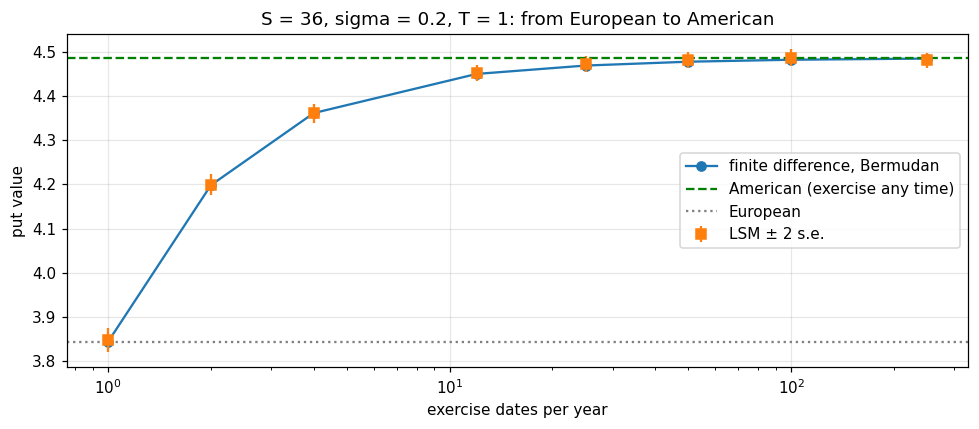

,exercise dates / yr,FD Bermudan,LSM,LSM s.e.,European
0,1,3.8442,3.8474,0.0137,3.8443
1,2,4.1984,4.1991,0.0119,3.8443
2,4,4.3615,4.3611,0.0105,3.8443
3,12,4.4500,4.4521,0.0095,3.8443
4,25,4.4690,4.4730,0.0093,3.8443
5,50,4.4777,4.4815,0.0092,3.8443
6,100,4.4821,4.4872,0.0093,3.8443
7,250,4.4848,4.4805,0.0090,3.8443


In [13]:
S0, sigma, T = 36, 0.2, 1
fd_cont = fd_put(S0, sigma, T, exercise_per_year=None)
grid = [1, 2, 4, 12, 25, 50, 100, 250]
rows = []
for m in grid:
    S, dt = simulate(S0, sigma, T, 50_000, seed=42, per_year=m)
    v, se, _ = lsm(S, dt)
    rows.append((m, fd_put(S0, sigma, T, exercise_per_year=m), v, se))
conv = pd.DataFrame(rows, columns=["exercise dates / yr", "FD Bermudan", "LSM", "LSM s.e."])
conv["European"] = bs_put(S0, sigma, T)
print(f"continuous-exercise American (FD): {fd_cont:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(conv["exercise dates / yr"], conv["FD Bermudan"], "o-", label="finite difference, Bermudan")
ax.errorbar(conv["exercise dates / yr"], conv.LSM, yerr=2 * conv["LSM s.e."], fmt="s", label="LSM ± 2 s.e.")
ax.axhline(fd_cont, color="green", ls="--", label="American (exercise any time)")
ax.axhline(conv.European[0], color="grey", ls=":", label="European")
ax.set_xscale("log"); ax.set_xlabel("exercise dates per year"); ax.set_ylabel("put value")
ax.set_title("S = 36, sigma = 0.2, T = 1: from European to American")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "exercise_dates.png"); plt.show()
conv.round(4)

- **With one date a year,** both methods give the European value (3.844), as they must.
- **Adding dates.** The value climbs quickly at first: four dates already capture most of the early-exercise premium. After that it flattens out towards the continuous-exercise value of 4.4865.
- **At 50 dates,** the paper's contract is worth 4.4777, so the gap to a true American put is about 0.9 cents. That's why the paper's finite-difference benchmark had to be Bermudan to be a fair comparison.
- **The two methods agree** within about 2 standard errors at every grid size. The largest gap is about half a cent, at 100 dates.

## 9. Do the numbers make sense?

- **The worked example is exact.** Any error in the backward induction or the regression would show up there, since the paths are fixed.
- **Black-Scholes matches all 20 printed European values.** Since the early-exercise premium is American minus European, any error here would contaminate every comparison.
- **The ordering is right everywhere:** European < Bermudan (50 dates) < American. Each extra exercise right can only add value.
- **The early-exercise premium behaves as theory says.** It's largest for in-the-money, low-volatility, long-dated puts (1.07 at spot 36, 20%, 2 years). Those are the cases where getting the strike early and earning interest on it beats waiting.
- **The standard errors are the right size.** They grow with volatility and maturity, and they match the paper's range (0.7–2.4 cents).

## 10. Is the procedure right?

- **The exercise decision uses only information available at that date:** today's price goes into the regression, and the realised future cash flows are only used to *fit* it, never to make the decision on a path directly. Table 2 checks that this doesn't inflate the price.
- **Only in-the-money paths go into the regression**, as the paper specifies. Section 6 shows that using all paths costs about 2 cents.
- **Exercise is allowed on the 50 dates per year after today, including expiry.** Today itself is excluded, matching the paper's set-up. An earlier draft of my finite-difference code wrongly allowed exercise today. It made no difference to Table 1, but it gave the wrong answer for the one-date case in Section 8, and that's how I caught it.
- **Rescaling by the strike before regressing** is done as the paper describes in Section 8.3. Section 3 shows it's essential.

## Wrapping up

This replication holds up well. The worked example and the 20 European values are exact. The finite-difference benchmark matches to a tenth of a cent on average, and its numbers also settle a question the text leaves open: the benchmark is the Bermudan option, not the American one. The simulated prices agree with the paper's row by row within sampling error, and the overfitting test behaves the same way.

The one loose end is a small, statistically clear difference in level: the paper's simulated prices sit about 0.6 cents lower than mine, relative to the same benchmark. I tested the obvious implementation differences, and none of them reproduces it on its own. Regressing on all paths or using fewer functions overshoots, Euler paths go the wrong way, and precision and exercise-date count make no difference. My best guess is a detail of their regression routine that the paper doesn't spell out. It's well below the 1/16-dollar tick the paper mentions for option prices, so it doesn't affect any of the paper's conclusions. It's reported here rather than hidden.

Two things I learned from doing it rather than reading it: the rescaling note in Section 8.3 is essential (without it the method is 6 cents off), and a single random seed shared across a whole table can make all its rows look biased in the same direction.

If I took this further I would:
- compute an upper bound with the Andersen–Broadie (2004) duality method, which gives an interval around the true price instead of a single estimate;
- price the paper's Section 4 American-Bermuda-Asian option, where finite differences need a second state variable and simulation shows its advantage;
- compare against a neural-network continuation function, the modern descendant of this regression.